# 4. Connectivity and Graph Properties
**Question:** How connected are the airports, and what do graph distances mean?

**Plan** (each step has a check):
1. Build the undirected airport graph from `routes.dat` → check node/edge counts, no self-loops.
2. Connected components → check sizes sum to node count.
3. Shortest paths, average path length, diameter → check against BFS on the giant component.
4. Triangles and clustering → compare with a random graph of the same size.
5. Show that distance = **route hops, not travel time** → compare hops with great-circle km.
6. Concise properties summary.

**Concepts (plain language)**
- *Walk*: any sequence of edges. *Path*: a walk that never revisits an airport. *Shortest path*: path with the fewest edges (hops).
- *Connected component*: a group where every airport can reach every other by some chain of flights.
- *Diameter*: the longest shortest path (the "worst-case" trip in hops). *Average path length*: typical hops between two random airports.
- *Triangle*: three airports all directly linked. *Local clustering coefficient*: of an airport's neighbours, the fraction that are also linked to each other.

In [1]:
import numpy as np, pandas as pd, networkx as nx
import matplotlib.pyplot as plt
from collections import Counter
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
DATA = "../data/"

## 1. Build the graph
**Assumptions:** nodes = airports (IATA code); an edge = at least one route between two airports in either direction; duplicates (many airlines on one pair) collapse into one edge; self-loops and rows with missing (`\N`) airport codes are dropped. Direction is ignored because we study structure, not travel direction.

In [2]:
cols = ["airline","airline_id","src","src_id","dst","dst_id","codeshare","stops","equipment"]
routes = pd.read_csv(DATA+"routes.dat", header=None, names=cols, na_values=["\\N"], keep_default_na=False)
acols = ["id","name","city","country","iata","icao","lat","lon","alt","tz","dst","tzdb","type","source"]
airports = pd.read_csv(DATA+"airports.dat", header=None, names=acols, na_values=["\\N"], keep_default_na=False)
airports = airports.dropna(subset=["iata"]).drop_duplicates("iata").set_index("iata")

r = routes.dropna(subset=["src","dst"])
r = r[r.src != r.dst]
edges = {tuple(sorted(e)) for e in zip(r.src, r.dst)}
G = nx.Graph(edges)
print(f"route rows: {len(routes):,} | usable: {len(r):,}")
print(f"nodes: {G.number_of_nodes():,} | edges (unique undirected): {G.number_of_edges():,}")
assert nx.number_of_selfloops(G) == 0
print("airports with coordinates:", sum(n in airports.index for n in G), "/", G.number_of_nodes())

route rows: 67,663 | usable: 67,662
nodes: 3,425 | edges (unique undirected): 19,256
airports with coordinates: 3262 / 3425


## 2. Connected components
If the network were split into islands, some airports could not be reached from others at all. We count the islands and their sizes.

In [3]:
comps = sorted(nx.connected_components(G), key=len, reverse=True)
sizes = [len(c) for c in comps]
assert sum(sizes) == G.number_of_nodes()
giant = G.subgraph(comps[0]).copy()
print(f"components: {len(comps)} | giant component: {sizes[0]:,} airports "
      f"({sizes[0]/G.number_of_nodes():.1%}) | is connected overall: {nx.is_connected(G)}")
print("next largest sizes:", sizes[1:11])
print("components of size <= 3:", sum(s <= 3 for s in sizes))
for c in comps[1:4]:
    print(sorted(c)[:6], [airports.country.get(a, "?") for a in sorted(c)[:3]])

components: 8 | giant component: 3,397 airports (99.2%) | is connected overall: False
next largest sizes: [10, 4, 4, 4, 2, 2, 2]
components of size <= 3: 3
['BMY', 'GEA', 'ILP', 'KNQ', 'KOC', 'LIF'] ['New Caledonia', 'New Caledonia', 'New Caledonia']
['AKB', 'DUT', 'IKO', 'KQA'] ['United States', 'United States', 'United States']
['ERS', 'MPA', 'NDU', 'OND'] ['Namibia', 'Namibia', 'Namibia']


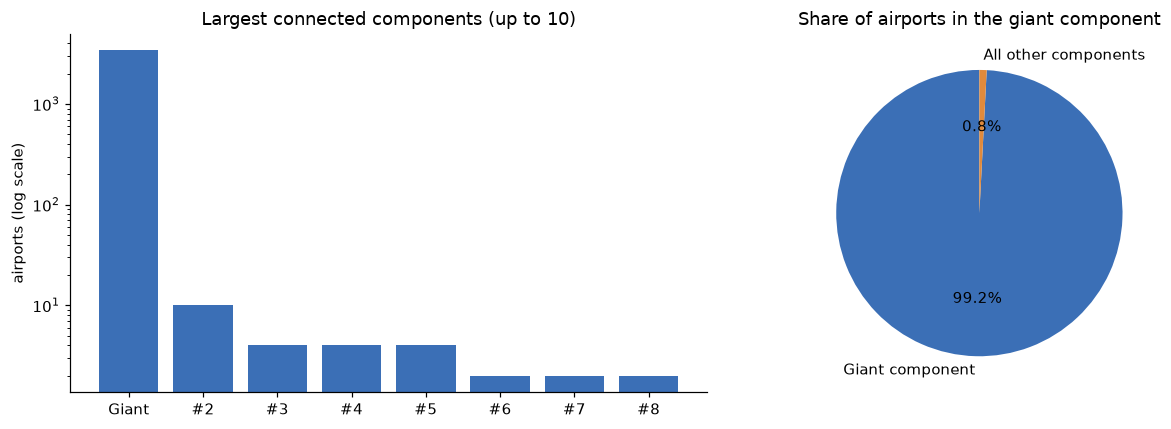

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
top = sizes[:10]; ax[0].bar(["Giant"] + [f"#{i}" for i in range(2, len(top)+1)], top, color="#3b6fb6")
ax[0].set_yscale("log"); ax[0].set_ylabel("airports (log scale)"); ax[0].set_title("Largest connected components (up to 10)")
ax[1].pie([sizes[0], G.number_of_nodes()-sizes[0]], labels=["Giant component","All other components"],
          autopct="%1.1f%%", colors=["#3b6fb6","#e08a3c"], startangle=90)
ax[1].set_title("Share of airports in the giant component")
plt.tight_layout(); plt.show()

**Reading the plot.** Almost the whole network is one giant component: from nearly any airport you can reach nearly any other by chaining flights. The small leftovers are isolated regional systems (e.g. remote island or domestic-only airline clusters) with no listed route into the main network. *Caveat:* `routes.dat` is a snapshot and incomplete, so "disconnected" means "no listed route", not necessarily "no real connection".

**Brief:** one giant component holds almost every airport; the rest are tiny islands.

## 3. Shortest paths, average path length, diameter
Path metrics are only defined within a connected piece, so we compute them on the **giant component**. With ~3,400 nodes we can run BFS from every airport and get exact values (no sampling).

In [5]:
# exact all-pairs hop distances on the giant component
dist = dict(nx.all_pairs_shortest_path_length(giant))
n = giant.number_of_nodes()
pair_d = np.array([d for s in dist.values() for d in s.values() if d > 0])   # ordered pairs, s != t
ecc = {s: max(v.values()) for s, v in dist.items()}
diameter, radius = max(ecc.values()), min(ecc.values())
avg_len = pair_d.mean()
# check against networkx built-ins
assert diameter == nx.diameter(giant, e=ecc) and abs(avg_len - nx.average_shortest_path_length(giant)) < 1e-9
print(f"giant component: {n:,} nodes, {giant.number_of_edges():,} edges")
print(f"average path length: {avg_len:.2f} hops | diameter: {diameter} hops | radius: {radius} hops")
print("share of pairs reachable in <=3 hops: %.1f%%" % (100*(pair_d <= 3).mean()))

giant component: 3,397 nodes, 19,230 edges
average path length: 4.10 hops | diameter: 13 hops | radius: 7 hops
share of pairs reachable in <=3 hops: 32.5%


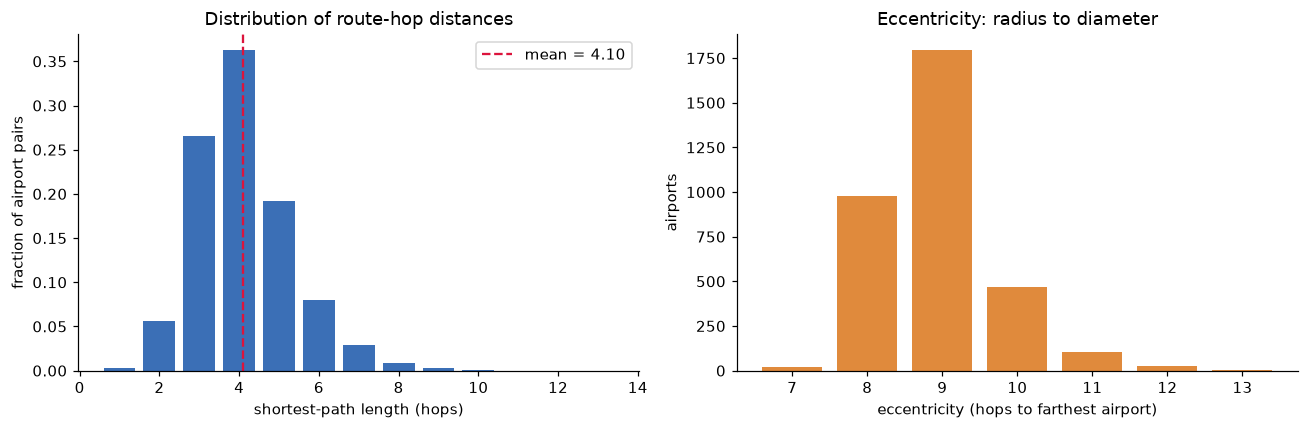

In [6]:
counts = Counter(pair_d); xs = sorted(counts)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(xs, [counts[x]/len(pair_d) for x in xs], color="#3b6fb6")
ax[0].axvline(avg_len, color="crimson", ls="--", label=f"mean = {avg_len:.2f}")
ax[0].set(xlabel="shortest-path length (hops)", ylabel="fraction of airport pairs", title="Distribution of route-hop distances")
ax[0].legend()
ec = Counter(ecc.values()); ks = sorted(ec)
ax[1].bar(ks, [ec[k] for k in ks], color="#e08a3c")
ax[1].set(xlabel="eccentricity (hops to farthest airport)", ylabel="airports", title="Eccentricity: radius to diameter")
plt.tight_layout(); plt.show()

**Reading the plots.** *Left:* most airport pairs are only a few hops apart (a "small-world" effect: a few big hubs shortcut the network). The red line is the average. *Right:* each airport's eccentricity is its worst-case hops; the smallest value is the **radius**, the largest is the **diameter**. Well-connected hubs sit near the radius, remote airports near the diameter.

**Brief:** typical trips need only a handful of hops; even the worst pair is bounded by the diameter.

### Where is the diameter? A concrete longest shortest path

13-hop path: QUV (?, ?) -> XEQ (?, ?) -> JNN (Nanortalik, Greenland) -> JJU (Qaqortoq, Greenland) -> UAK (Narssarssuaq, Greenland) -> SFJ (Sondrestrom, Greenland) -> CPH (Copenhagen, Denmark) -> YYZ (Toronto, Canada) -> YUL (Montreal, Canada) -> YVP (Quujjuaq, Canada) -> YPX (Puvirnituq, Canada) -> AKV (Akulivik, Canada) -> YIK (Ivujivik, Canada) -> YZG (Salluit, Canada)


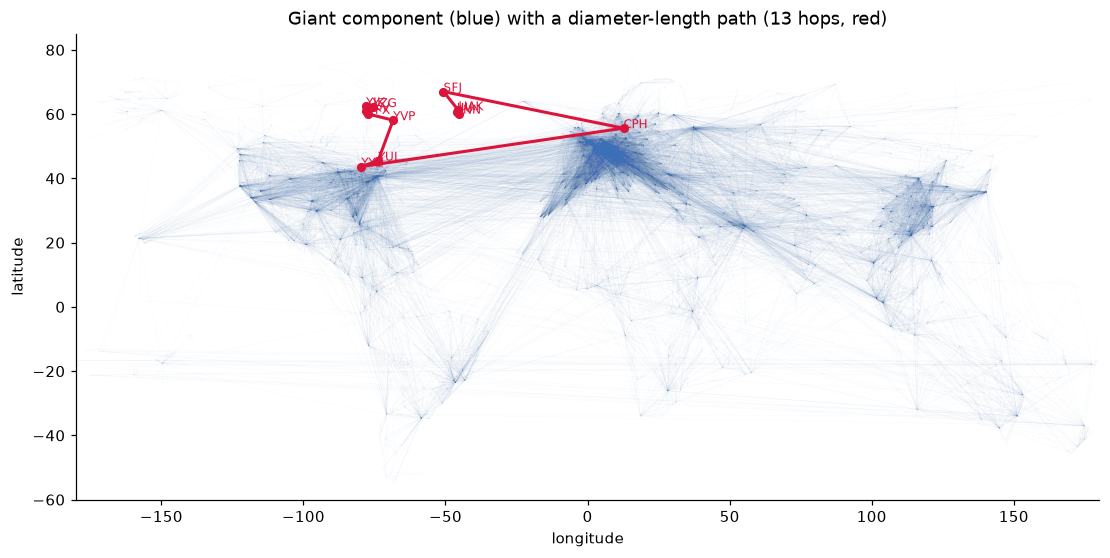

In [7]:
src = next(s for s, e in ecc.items() if e == diameter)
dst = next(t for t, d in dist[src].items() if d == diameter)
path = nx.shortest_path(giant, src, dst)
nm = lambda a: f"{a} ({airports.city.get(a, '?')}, {airports.country.get(a, '?')})"
print(f"{diameter}-hop path:", " -> ".join(nm(a) for a in path))

def draw_map(ax, graph, highlight=None, alpha=0.04):
    for u, v in graph.edges():
        if u in airports.index and v in airports.index:
            ax.plot([airports.lon[u], airports.lon[v]], [airports.lat[u], airports.lat[v]],
                    color="#3b6fb6", lw=0.3, alpha=alpha)
    if highlight:
        pts = [(airports.lon[a], airports.lat[a]) for a in highlight if a in airports.index]
        ax.plot(*zip(*pts), "-o", color="crimson", lw=2, ms=5)
        for a in highlight:
            if a in airports.index: ax.annotate(a, (airports.lon[a], airports.lat[a]), fontsize=8, color="crimson")
    ax.set(xlim=(-180, 180), ylim=(-60, 85), xlabel="longitude", ylabel="latitude")

fig, ax = plt.subplots(figsize=(12, 5.5))
draw_map(ax, giant, path); ax.set_title(f"Giant component (blue) with a diameter-length path ({diameter} hops, red)")
plt.show()

**Reading the map.** Blue lines are all routes in the giant component; the red path is one of the "farthest" airport pairs. The diameter is driven by peripheral airports that reach the core only through a chain of small feeder routes.

## 4. Distance is route hops, not travel time
A graph edge has no length unless we give it one. Our distance counts **edges** only. Below we compare hops with the real great-circle distance (km) for random airport pairs. If hops measured travel, the two would line up; they do not.

In [8]:
def haversine(a, b):
    la1, lo1, la2, lo2 = map(np.radians, [airports.lat[a], airports.lon[a], airports.lat[b], airports.lon[b]])
    h = np.sin((la2-la1)/2)**2 + np.cos(la1)*np.cos(la2)*np.sin((lo2-lo1)/2)**2
    return 2*6371*np.arcsin(np.sqrt(h))

rng = np.random.default_rng(0)
nodes = [a for a in giant if a in airports.index]
pairs = [tuple(rng.choice(nodes, 2, replace=False)) for _ in range(4000)]
dd = pd.DataFrame({"hops": [dist[a][b] for a, b in pairs], "km": [haversine(a, b) for a, b in pairs]})
print("correlation hops vs km: %.2f" % dd.hops.corr(dd.km))
print(dd.groupby("hops").km.agg(["count", "median", "max"]).round(0))
# a 1-hop pair that is physically far, a 3+ hop pair that is physically close
far1 = max(((a, b) for a, b in giant.edges() if a in airports.index and b in airports.index), key=lambda e: haversine(*e))
print("\nlongest single hop:", far1, f"{haversine(*far1):,.0f} km")
close = dd[(dd.hops >= 3)].nsmallest(1, "km").index[0]; a, b = pairs[close]
print(f"close but many hops: {a}-{b}: {dd.hops[close]} hops, {dd.km[close]:,.0f} km")

correlation hops vs km: 0.35
      count   median      max
hops                         
1        21   1019.0  10237.0
2       271   2950.0  18782.0
3      1175   7066.0  18225.0
4      1443   9248.0  19811.0
5       716  10120.0  19389.0
6       275   9655.0  18738.0
7        73   9953.0  18777.0
8        20   9694.0  17843.0
9         6   7962.0  13097.0



longest single hop: ('SYD', 'DFW') 13,808 km
close but many hops: IMT-PLN: 3 hops, 259 km


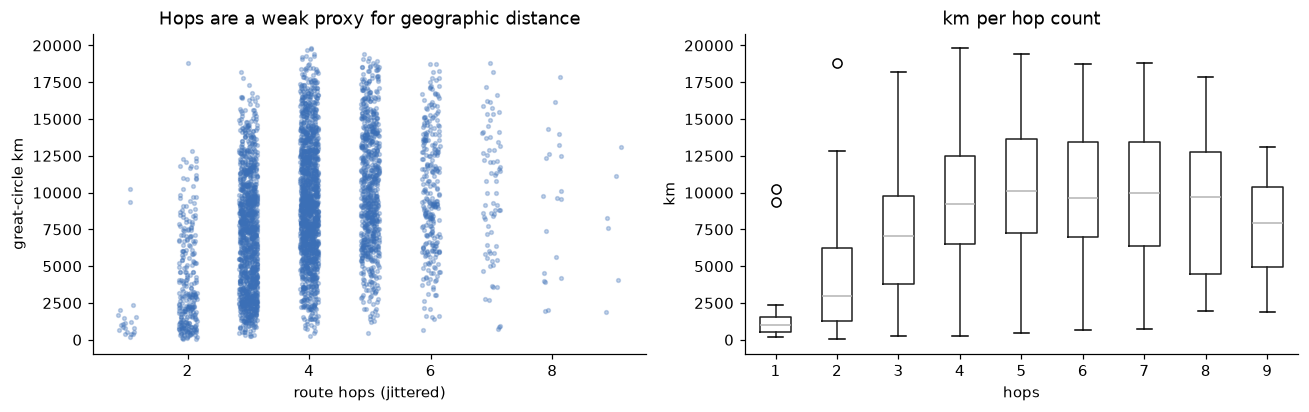

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
jit = dd.hops + rng.uniform(-0.15, 0.15, len(dd))
ax[0].scatter(jit, dd.km, s=6, alpha=0.3, color="#3b6fb6")
ax[0].set(xlabel="route hops (jittered)", ylabel="great-circle km", title="Hops are a weak proxy for geographic distance")
dd.boxplot(column="km", by="hops", ax=ax[1], grid=False); ax[1].set(title="km per hop count", xlabel="hops", ylabel="km")
plt.suptitle(""); plt.tight_layout(); plt.show()

**Reading the plots.** For each hop count, the km range is huge and overlapping: a 1-hop route can span an ocean, while a 3-hop trip can join two nearby towns that lack a direct flight. Hops also ignore layover time, flight duration, frequency, price and airline alliances.

**Brief:** distance here means *number of flights chained*, never time or kilometres.

## 5. Triangles and clustering
A triangle means A–B, B–C and A–C all exist. High clustering means an airport's neighbours also tend to be linked (regional clusters). We compare with an Erdős–Rényi random graph with the same node/edge count to see if clustering is more than chance.

In [10]:
tri = nx.triangles(G)
n_triangles = sum(tri.values()) // 3
cc = nx.clustering(G)
avg_cc, trans = nx.average_clustering(G), nx.transitivity(G)
rand = nx.gnm_random_graph(G.number_of_nodes(), G.number_of_edges(), seed=0)
print(f"triangles: {n_triangles:,}")
print(f"average local clustering: {avg_cc:.3f} | global clustering (transitivity): {trans:.3f}")
print(f"random graph same size  : avg {nx.average_clustering(rand):.3f}, transitivity {nx.transitivity(rand):.3f}")
# tiny worked example of the definition
H = nx.Graph([("A","B"),("A","C"),("A","D"),("B","C")])
print("toy: clustering of A =", nx.clustering(H, "A"), "(1 of 3 neighbour pairs linked)")
assert nx.clustering(H, "A") == 1/3

triangles: 101,117
average local clustering: 0.487 | global clustering (transitivity): 0.248
random graph same size  : avg 0.003, transitivity 0.004
toy: clustering of A = 0.3333333333333333 (1 of 3 neighbour pairs linked)


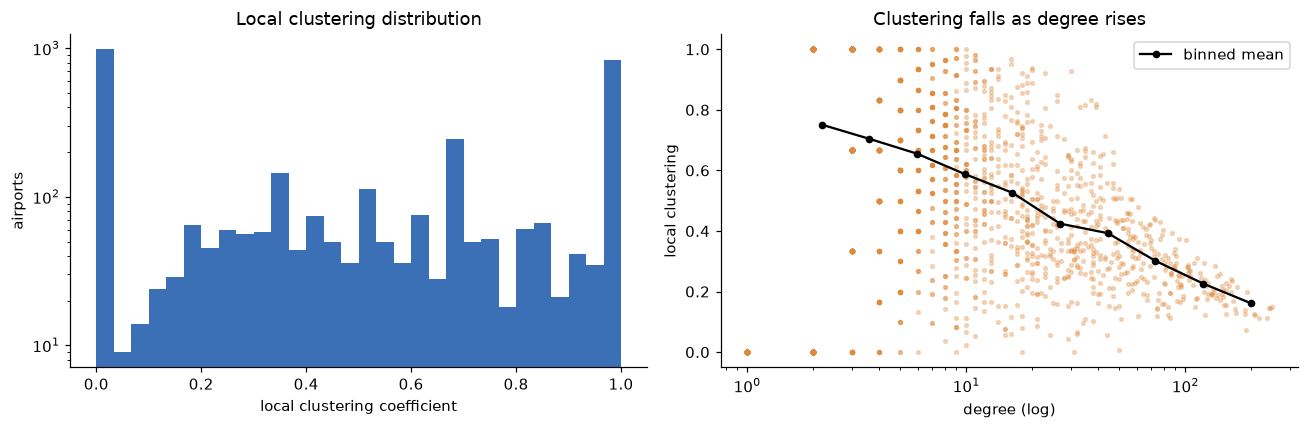

top triangle airports: [('AMS', 4543), ('FRA', 4357), ('CDG', 4136), ('MUC', 3658), ('LHR', 3168)]


In [11]:
deg = dict(G.degree())
df = pd.DataFrame({"deg": pd.Series(deg), "cc": pd.Series(cc)})
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(df.cc, bins=30, color="#3b6fb6"); ax[0].set(xlabel="local clustering coefficient", ylabel="airports", yscale="log", title="Local clustering distribution")
ax[1].scatter(df.deg, df.cc, s=6, alpha=0.3, color="#e08a3c"); ax[1].set_xscale("log")
bins = df[df.deg>1].groupby(pd.cut(df.deg[df.deg>1], np.logspace(0, np.log10(df.deg.max()), 12)), observed=True).cc.mean()
ax[1].plot([iv.mid for iv in bins.index], bins.values, "k-o", ms=4, label="binned mean"); ax[1].legend()
ax[1].set(xlabel="degree (log)", ylabel="local clustering", title="Clustering falls as degree rises")
plt.tight_layout(); plt.show()
print("top triangle airports:", sorted(tri.items(), key=lambda x: -x[1])[:5])

**Reading the plots.** *Left:* many airports have clustering 0 (neighbours unconnected, e.g. spokes of one hub) and many have 1 (a tiny fully linked group). *Right:* low-degree airports tend to have high clustering (their few neighbours are mutually linked, such as regional cliques), while big hubs have low clustering because they link otherwise unrelated places. The real network's clustering is far above the random graph's, so routes are organised regionally rather than randomly.

**Brief:** clustering far exceeds chance; hubs connect, small airports cluster.

## 6. Concise properties summary

In [12]:
summary = pd.Series({
    "Airports (nodes)": G.number_of_nodes(),
    "Unique undirected routes (edges)": G.number_of_edges(),
    "Density": round(nx.density(G), 4),
    "Connected components": len(comps),
    "Giant component size (share)": f"{sizes[0]:,} ({sizes[0]/G.number_of_nodes():.1%})",
    "Average path length (hops, giant)": round(avg_len, 2),
    "Diameter / radius (hops, giant)": f"{diameter} / {radius}",
    "Triangles": n_triangles,
    "Average local clustering": round(avg_cc, 3),
    "Transitivity": round(trans, 3),
    "Random-graph clustering (same size)": round(nx.average_clustering(rand), 4),
}, name="value").to_frame()
summary

,value
Airports (nodes),3425
Unique undirected routes (edges),19256
Density,0.0033
Connected components,8
Giant component size (share),"3,397 (99.2%)"
"Average path length (hops, giant)",4.1
"Diameter / radius (hops, giant)",13 / 7
Triangles,101117
Average local clustering,0.487
Transitivity,0.248


## Takeaways and limits
- **Connectivity:** one giant component contains nearly all airports; a few small islands remain.
- **Distances:** small average path length and modest diameter (small-world); distance = **hops**, not km or time.
- **Clustering:** much higher than random; hubs act as bridges, small airports form local groups.
- **Limits:** undirected, duplicates collapsed, unweighted; the route data is a static snapshot, so "disconnected" means "no listed route". Path/diameter use the giant component only. Structural results do not capture capacity, frequency or schedules.